In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import classification_report, confusion_matrix

print(f"TensorFlow version : {tf.__version__}")
print(f"Keras version      : {keras.__version__}")
print(f"GPU available      : {tf.config.list_physical_devices('GPU')}")

TensorFlow version : 2.20.0
Keras version      : 3.13.2
GPU available      : []


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

── Dataset shapes ──
X_train : (60000, 28, 28)  |  y_train : (60000,)
X_test  : (10000, 28, 28)   |  y_test  : (10000,)
Pixel range before normalisation: [0, 255]
Classes : [0 1 2 3 4 5 6 7 8 9]


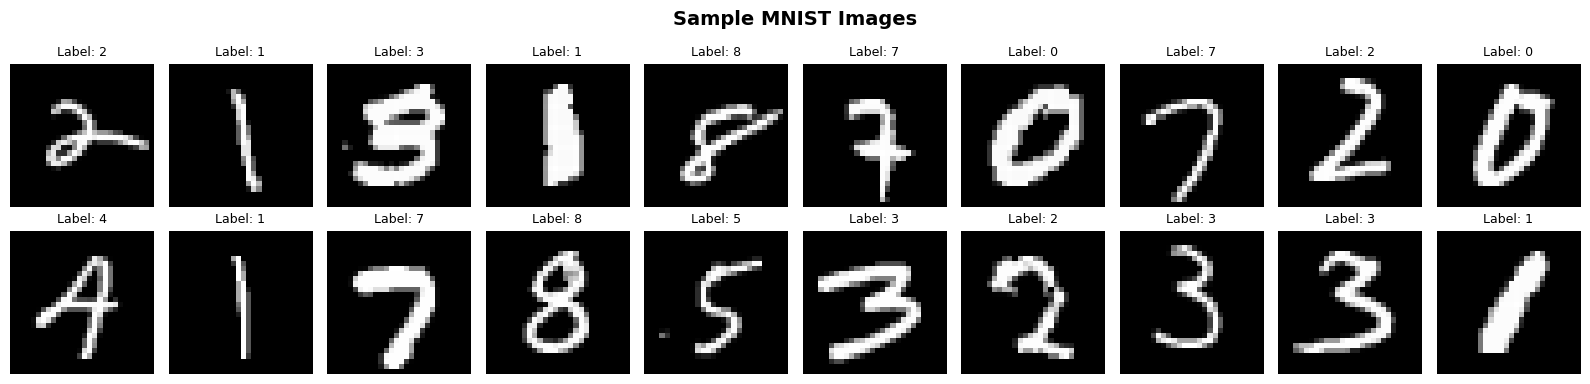

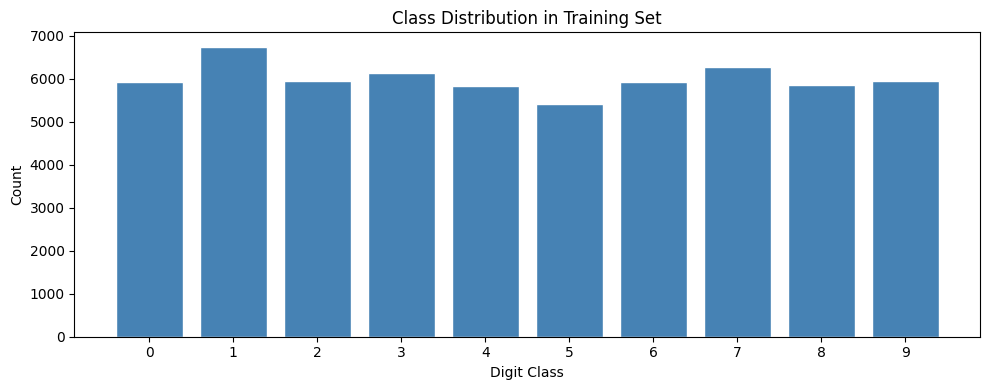

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

print("\n── Dataset shapes ──")
print(f"X_train : {X_train.shape}  |  y_train : {y_train.shape}")
print(f"X_test  : {X_test.shape}   |  y_test  : {y_test.shape}")
print(f"Pixel range before normalisation: [{X_train.min()}, {X_train.max()}]")
print(f"Classes : {np.unique(y_train)}")

# Visualise a sample of training images
fig, axes = plt.subplots(2, 10, figsize=(16, 4))
fig.suptitle("Sample MNIST Images", fontsize=14, fontweight="bold")
for i, ax in enumerate(axes.flat):
    idx = np.random.randint(0, len(X_train))
    ax.imshow(X_train[idx], cmap="gray")
    ax.set_title(f"Label: {y_train[idx]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

# Class distribution
plt.figure(figsize=(10, 4))
plt.bar(range(10), np.bincount(y_train), color="steelblue", edgecolor="white")
plt.xticks(range(10))
plt.xlabel("Digit Class")
plt.ylabel("Count")
plt.title("Class Distribution in Training Set")
plt.tight_layout()
plt.show()

In [3]:
X_train = X_train.astype("float32") / 255.0
X_test  = X_test.astype("float32")  / 255.0

# Add channel dimension → (batch, 28, 28, 1)
X_train = X_train[..., np.newaxis]
X_test  = X_test[..., np.newaxis]

# One-hot encode labels
NUM_CLASSES = 10
y_train_ohe = keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test_ohe  = keras.utils.to_categorical(y_test,  NUM_CLASSES)

print("After preprocessing:")
print(f"X_train : {X_train.shape}  pixel range [{X_train.min():.2f}, {X_train.max():.2f}]")
print(f"y_train_ohe : {y_train_ohe.shape}")

After preprocessing:
X_train : (60000, 28, 28, 1)  pixel range [0.00, 1.00]
y_train_ohe : (60000, 10)


In [4]:
def build_model(input_shape=(28, 28, 1), num_classes=10):
    """
    CNN Architecture:
      Conv → BN → ReLU → Pool (×2 blocks)
      Flatten → Dense → Dropout → Softmax
    """
    model = keras.Sequential([
        # ── Block 1 ──
        layers.Conv2D(32, (3, 3), padding="same", input_shape=input_shape),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(32, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # ── Block 2 ──
        layers.Conv2D(64, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(64, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # ── Classifier ──
        layers.Flatten(),
        layers.Dense(256),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation="softmax"),
    ], name="MNIST_CNN")

    return model

model = build_model()
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "MNIST_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       803,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 872,426 (3.33 MB)

 Trainable params: 871,530 (3.32 MB)

 Non-trainable params: 896 (3.50 KB)

In [5]:
LEARNING_RATE = 1e-3

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

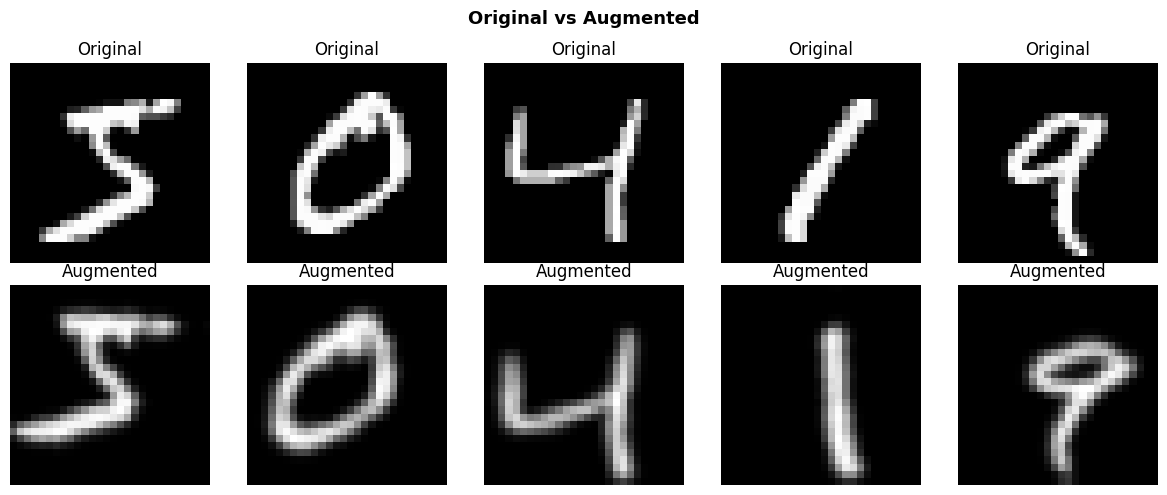

In [6]:
data_augmentation = keras.Sequential([
    layers.RandomRotation(factor=0.1),          # ±10 %  rotation
    layers.RandomZoom(height_factor=0.1),        # ±10 %  zoom
    layers.RandomTranslation(0.1, 0.1),          # ±10 %  shift
], name="augmentation")

# Visualise augmented images
sample_imgs = X_train[:5]
aug_imgs    = data_augmentation(sample_imgs, training=True).numpy()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("Original vs Augmented", fontsize=13, fontweight="bold")
for i in range(5):
    axes[0, i].imshow(sample_imgs[i, :, :, 0], cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")
    axes[1, i].imshow(aug_imgs[i, :, :, 0], cmap="gray")
    axes[1, i].set_title("Augmented")
    axes[1, i].axis("off")
plt.tight_layout()
plt.show()

In [7]:
BATCH_SIZE = 128

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train_ohe))
    .shuffle(60_000)
    .batch(BATCH_SIZE)
    .map(lambda x, y: (data_augmentation(x, training=True), y),
         num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test_ohe))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

In [8]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1,
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1,
    ),
    keras.callbacks.ModelCheckpoint(
        filepath="best_mnist_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1,
    ),
]

In [9]:
EPOCHS = 30

history = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    callbacks=callbacks,
    verbose=1,
)

print("\n✅ Training complete!")

Epoch 1/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 588ms/step - accuracy: 0.7527 - loss: 0.7744
Epoch 1: val_accuracy improved from None to 0.61580, saving model to best_mnist_model.keras

Epoch 1: finished saving model to best_mnist_model.keras
469/469 ━━━━━━━━━━━━━━━━━━━━ 291s 610ms/step - accuracy: 0.8716 - loss: 0.4081 - val_accuracy: 0.6158 - val_loss: 1.1916 - learning_rate: 0.0010
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 590ms/step - accuracy: 0.9489 - loss: 0.1683
Epoch 2: val_accuracy improved from 0.61580 to 0.94750, saving model to best_mnist_model.keras

Epoch 2: finished saving model to best_mnist_model.keras
469/469 ━━━━━━━━━━━━━━━━━━━━ 322s 611ms/step - accuracy: 0.9552 - loss: 0.1481 - val_accuracy: 0.9475 - val_loss: 0.1679 - learning_rate: 0.0010
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 584ms/step - accuracy: 0.9642 - loss: 0.1168
Epoch 3: val_accuracy improved from 0.94750 to 0.97560, saving model to best_mnist_model.keras

Epoch 3: finished saving model to best_mnist_mo

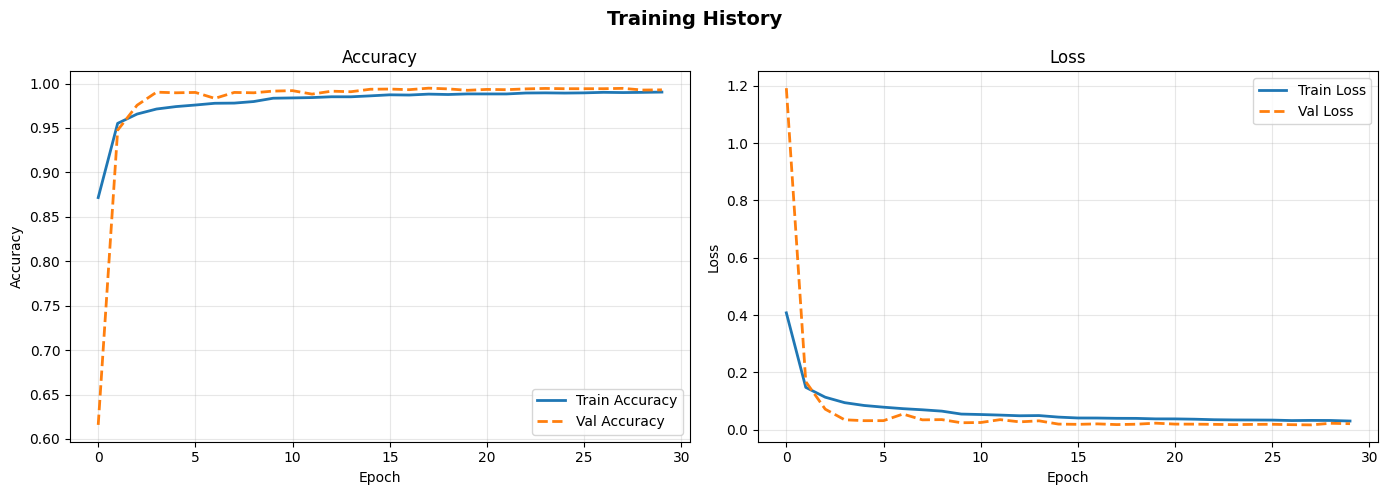

In [10]:
def plot_history(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Training History", fontsize=14, fontweight="bold")

    # Accuracy
    ax1.plot(history.history["accuracy"],     label="Train Accuracy", lw=2)
    ax1.plot(history.history["val_accuracy"], label="Val Accuracy",   lw=2, linestyle="--")
    ax1.set_title("Accuracy")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Accuracy")
    ax1.legend()
    ax1.grid(alpha=0.3)

    # Loss
    ax2.plot(history.history["loss"],     label="Train Loss", lw=2)
    ax2.plot(history.history["val_loss"], label="Val Loss",   lw=2, linestyle="--")
    ax2.set_title("Loss")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Loss")
    ax2.legend()
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(history)

In [11]:
test_loss, test_acc = model.evaluate(val_ds, verbose=0)
print(f"\n── Test Results ──")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc * 100:.2f}%")


── Test Results ──
Test Loss     : 0.0172
Test Accuracy : 99.46%


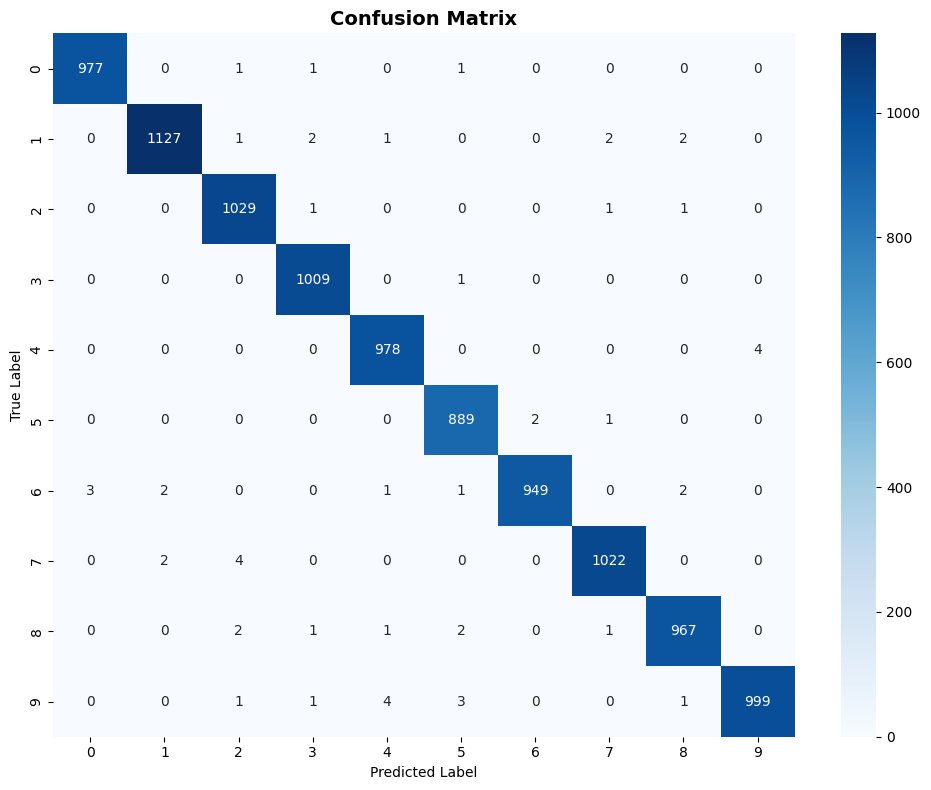


── Classification Report ──
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       980
           1       1.00      0.99      0.99      1135
           2       0.99      1.00      0.99      1032
           3       0.99      1.00      1.00      1010
           4       0.99      1.00      0.99       982
           5       0.99      1.00      0.99       892
           6       1.00      0.99      0.99       958
           7       1.00      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       1.00      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [12]:
y_pred_probs = model.predict(X_test, verbose=0)
y_pred       = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10),
)
plt.title("Confusion Matrix", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

print("\n── Classification Report ──")
print(classification_report(y_test, y_pred, target_names=[str(i) for i in range(10)]))

/tmp/ipykernel_9899/758727547.py:14: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_9899/758727547.py:14: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


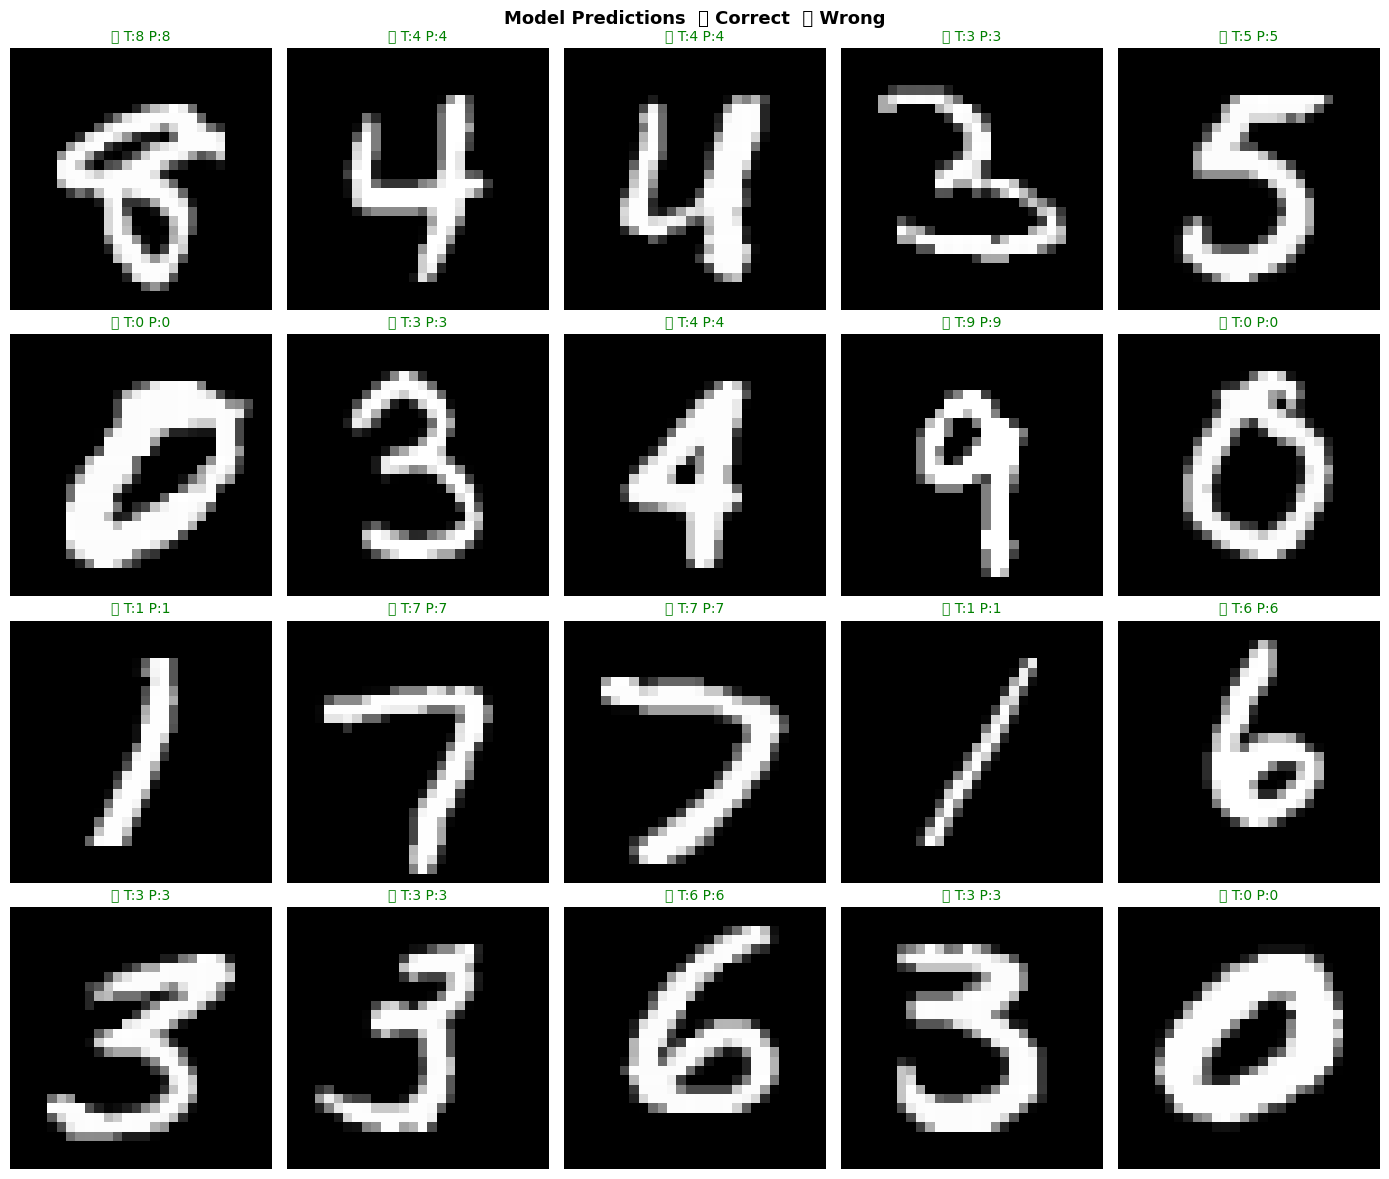

In [13]:
def visualise_predictions(X, y_true, y_pred, n=20):
    indices = np.random.choice(len(X), n, replace=False)
    fig, axes = plt.subplots(4, 5, figsize=(14, 12))
    fig.suptitle("Model Predictions  ✅ Correct  ❌ Wrong", fontsize=13, fontweight="bold")

    for ax, idx in zip(axes.flat, indices):
        ax.imshow(X[idx, :, :, 0], cmap="gray")
        true, pred = y_true[idx], y_pred[idx]
        colour  = "green" if true == pred else "red"
        icon    = "✅" if true == pred else "❌"
        ax.set_title(f"{icon} T:{true} P:{pred}", color=colour, fontsize=10)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

visualise_predictions(X_test, y_test, y_pred)

Total misclassified: 54 / 10000  (0.54%)


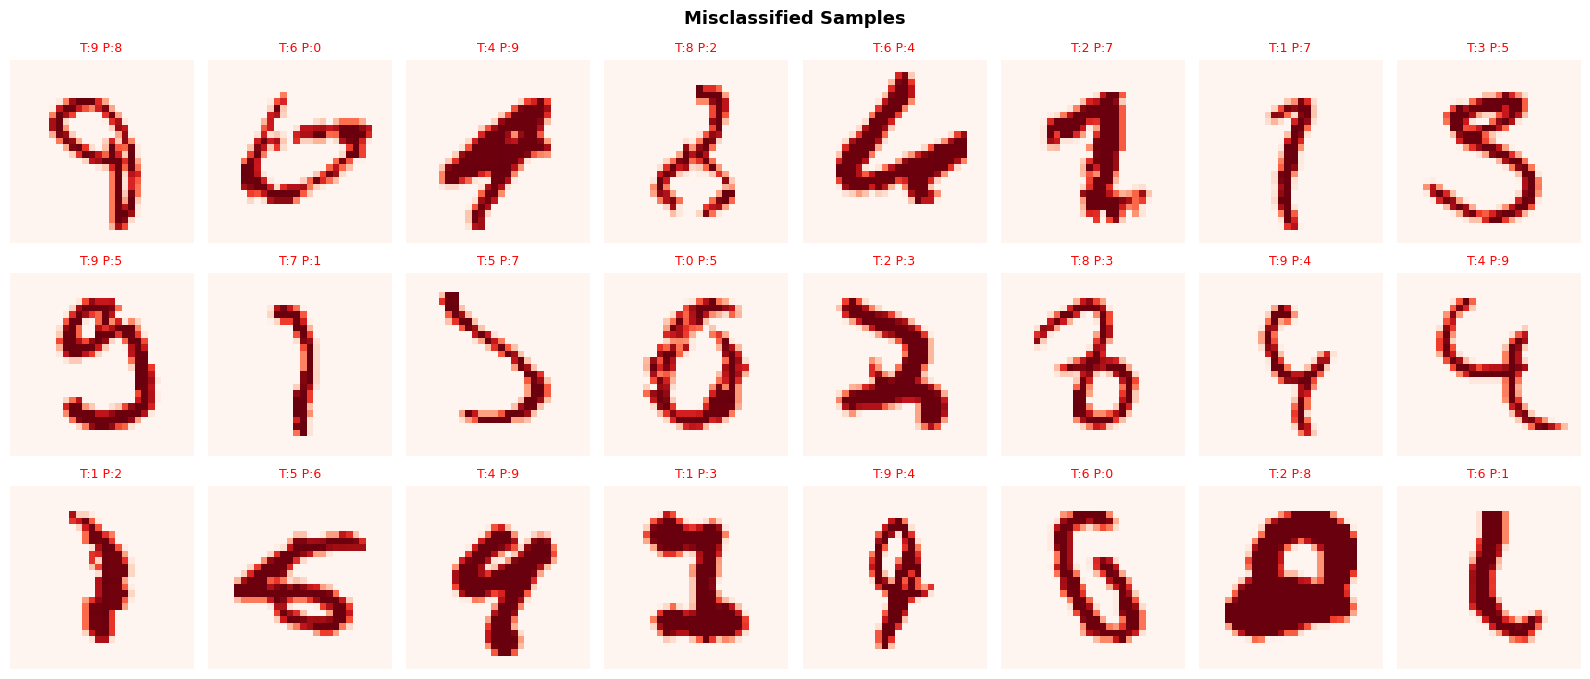

In [14]:
wrong_idx = np.where(y_pred != y_test)[0]
print(f"Total misclassified: {len(wrong_idx)} / {len(y_test)}"
      f"  ({len(wrong_idx)/len(y_test)*100:.2f}%)")

fig, axes = plt.subplots(3, 8, figsize=(16, 7))
fig.suptitle("Misclassified Samples", fontsize=13, fontweight="bold")
for ax, idx in zip(axes.flat, wrong_idx[:24]):
    ax.imshow(X_test[idx, :, :, 0], cmap="Reds")
    ax.set_title(f"T:{y_test[idx]} P:{y_pred[idx]}", fontsize=9, color="red")
    ax.axis("off")
plt.tight_layout()
plt.show()

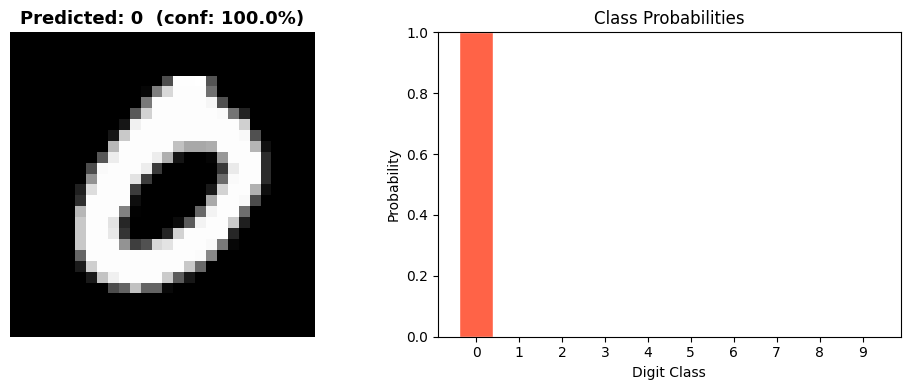

True label : 0
Predicted  : 0
Confidence : 100.00%


In [15]:
def predict_single(model, image_array):
    """
    image_array : numpy array shape (28, 28) or (28, 28, 1), values in [0, 1]
    """
    if image_array.ndim == 2:
        image_array = image_array[..., np.newaxis]
    img_batch = image_array[np.newaxis, ...]          # (1, 28, 28, 1)
    probs     = model.predict(img_batch, verbose=0)[0]
    pred      = np.argmax(probs)

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(image_array[:, :, 0], cmap="gray")
    plt.title(f"Predicted: {pred}  (conf: {probs[pred]*100:.1f}%)",
              fontsize=13, fontweight="bold")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    colors = ["steelblue"] * 10
    colors[pred] = "tomato"
    plt.bar(range(10), probs, color=colors, edgecolor="white")
    plt.xticks(range(10))
    plt.xlabel("Digit Class")
    plt.ylabel("Probability")
    plt.title("Class Probabilities")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

    return pred, probs

# Demo on a random test image
sample_idx = np.random.randint(0, len(X_test))
pred_digit, probs = predict_single(model, X_test[sample_idx])
print(f"True label : {y_test[sample_idx]}")
print(f"Predicted  : {pred_digit}")
print(f"Confidence : {probs[pred_digit]*100:.2f}%")

In [16]:
model.save("mnist_cnn_final.keras")
print("Model saved → mnist_cnn_final.keras")

# Load and verify
loaded_model = keras.models.load_model("mnist_cnn_final.keras")
_, loaded_acc = loaded_model.evaluate(X_test, y_test_ohe, verbose=0)
print(f"Loaded model accuracy : {loaded_acc * 100:.2f}%")

Model saved → mnist_cnn_final.keras
Loaded model accuracy : 99.46%


In [17]:
total_params     = model.count_params()
trainable_params = sum(np.prod(v.shape) for v in model.trainable_weights)

print("\n── Model Statistics ──")
print(f"Total parameters      : {total_params:,}")
print(f"Trainable parameters  : {trainable_params:,}")
print(f"Final test accuracy   : {test_acc * 100:.2f}%")
print(f"Final test loss       : {test_loss:.4f}")
print(f"Total misclassified   : {len(wrong_idx)} / {len(y_test)}")
print(f"Error rate            : {len(wrong_idx)/len(y_test)*100:.2f}%")


── Model Statistics ──
Total parameters      : 872,426
Trainable parameters  : 871,530
Final test accuracy   : 99.46%
Final test loss       : 0.0172
Total misclassified   : 54 / 10000
Error rate            : 0.54%


In [18]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from google.colab import files
from PIL import Image
import io

In [19]:
def preprocess_image(img: Image.Image) -> np.ndarray:
    """
    Accepts a PIL Image (any size, RGB or RGBA or grayscale).
    Returns a numpy array of shape (1, 28, 28, 1) with values in [0, 1],
    matching the format the MNIST model expects.
    """
    # 1. Convert to grayscale
    img = img.convert("L")

    # 2. Resize to 28×28 (MNIST size) using high-quality downsampling
    img = img.resize((28, 28), Image.LANCZOS)

    # 3. Convert to numpy array and normalise
    arr = np.array(img, dtype="float32") / 255.0

    # 4. MNIST digits are WHITE on BLACK background.
    #    Most drawn/photographed digits are BLACK on WHITE — invert them.
    if arr.mean() > 0.5:          # background is light → invert
        arr = 1.0 - arr

    # 5. Add batch and channel dimensions → (1, 28, 28, 1)
    return arr[np.newaxis, ..., np.newaxis]

📂 Click 'Choose Files' and upload one or more digit images …


Saving 3.png to 3.png

── Processing: 3.png ──


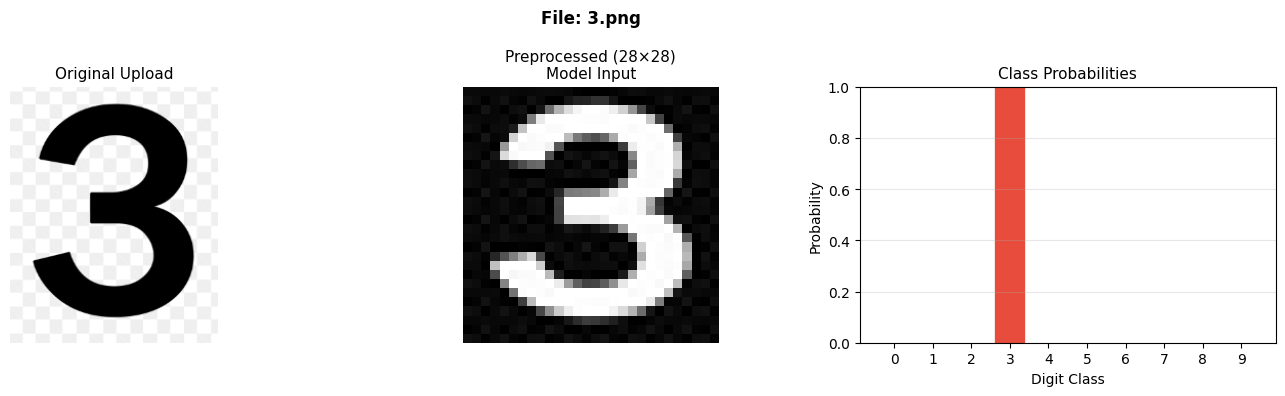

  🔢 Predicted Digit : 3
  💯 Confidence      : 100.00%
  📊 All probabilities:
     0:                                 0.00%
     1:                                 0.00%
     2:                                 0.00%
     3: █████████████████████████████  100.00% ← predicted
     4:                                 0.00%
     5:                                 0.00%
     6:                                 0.00%
     7:                                 0.00%
     8:                                 0.00%
     9:                                 0.00%


In [22]:
def upload_and_predict(model):
    """
    Opens a file-picker, preprocesses every uploaded image,
    and shows a rich prediction panel for each.
    """
    print("📂 Click 'Choose Files' and upload one or more digit images …")
    uploaded = files.upload()

    if not uploaded:
        print("⚠️  No file uploaded.")
        return

    for filename, raw_bytes in uploaded.items():
        print(f"\n── Processing: {filename} ──")

        # Open with PIL
        try:
            pil_img = Image.open(io.BytesIO(raw_bytes))
        except Exception as e:
            print(f"  ❌ Could not open image: {e}")
            continue

        # Preprocess
        processed = preprocess_image(pil_img)           # (1, 28, 28, 1)

        # Predict
        probs     = model.predict(processed, verbose=0)[0]   # (10,)
        pred      = int(np.argmax(probs))
        confidence = probs[pred] * 100

        # ── Plot ──────────────────────────────────────────────
        fig, axes = plt.subplots(1, 3, figsize=(14, 4))
        fig.suptitle(f"File: {filename}", fontsize=12, fontweight="bold")

        # Panel 1 — original upload
        axes[0].imshow(np.array(pil_img.convert("L")), cmap="gray")
        axes[0].set_title("Original Upload", fontsize=11)
        axes[0].axis("off")

        # Panel 2 — preprocessed (what model sees)
        axes[1].imshow(processed[0, :, :, 0], cmap="gray")
        axes[1].set_title("Preprocessed (28×28)\nModel Input", fontsize=11)
        axes[1].axis("off")

        # Panel 3 — probability bar chart
        colors = ["#4a90d9"] * 10
        colors[pred] = "#e74c3c"          # highlight predicted class in red
        axes[2].bar(range(10), probs, color=colors, edgecolor="white", linewidth=0.5)
        axes[2].set_xticks(range(10))
        axes[2].set_xlabel("Digit Class")
        axes[2].set_ylabel("Probability")
        axes[2].set_ylim(0, 1)
        axes[2].set_title("Class Probabilities", fontsize=11)
        axes[2].grid(axis="y", alpha=0.3)

        plt.tight_layout()
        plt.show()

        # ── Console summary ───────────────────────────────────
        print(f"  🔢 Predicted Digit : {pred}")
        print(f"  💯 Confidence      : {confidence:.2f}%")
        print(f"  📊 All probabilities:")
        for digit, prob in enumerate(probs):
            bar   = "█" * int(prob * 30)
            flag  = " ← predicted" if digit == pred else ""
            print(f"     {digit}: {bar:<30} {prob*100:5.2f}%{flag}")

# Run the uploader
upload_and_predict(model)

/tmp/ipykernel_9899/3147370814.py:29: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


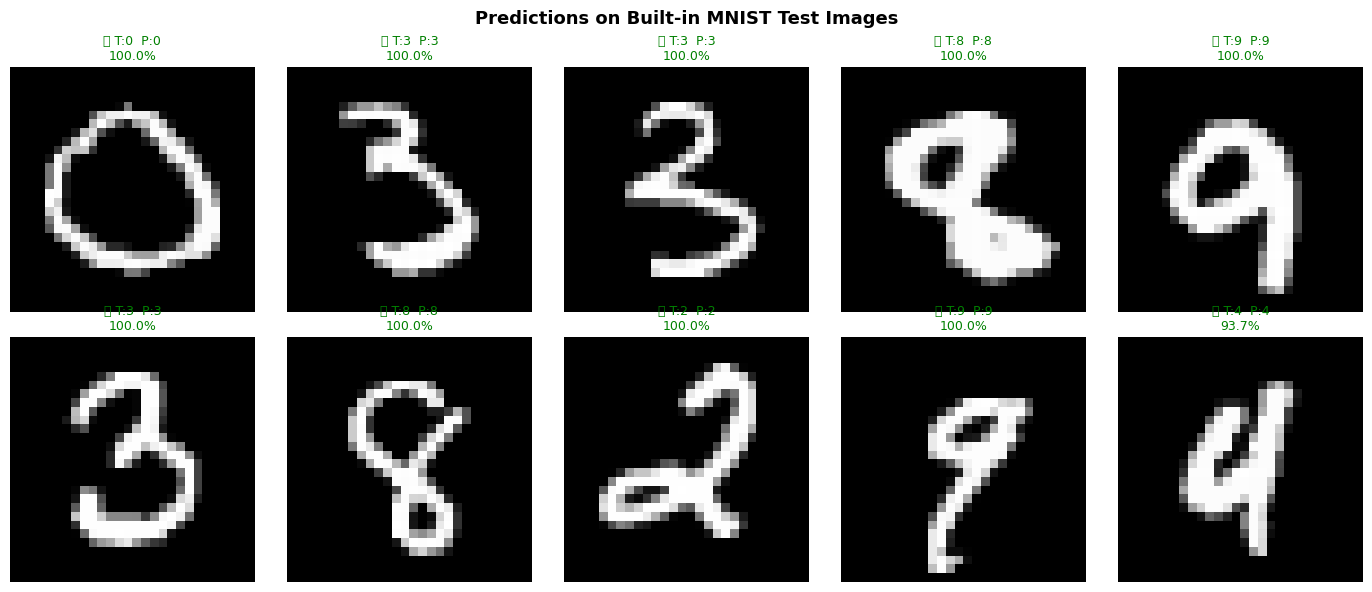

Accuracy on this batch: 10/10  (100%)


In [23]:
(_, _), (X_test, y_test) = keras.datasets.mnist.load_data()
X_test = X_test.astype("float32") / 255.0
X_test = X_test[..., np.newaxis]

def predict_from_test_set(model, X_test, y_test, n=10):
    """Pick n random MNIST test images and show predictions."""
    indices = np.random.choice(len(X_test), n, replace=False)

    fig, axes = plt.subplots(2, 5, figsize=(14, 6))
    fig.suptitle("Predictions on Built-in MNIST Test Images", fontsize=13, fontweight="bold")

    correct = 0
    for ax, idx in zip(axes.flat, indices):
        img_batch = X_test[idx][np.newaxis]           # (1, 28, 28, 1)
        probs     = model.predict(img_batch, verbose=0)[0]
        pred      = int(np.argmax(probs))
        true      = int(y_test[idx])
        conf      = probs[pred] * 100

        ax.imshow(X_test[idx, :, :, 0], cmap="gray")
        color = "green" if pred == true else "red"
        icon  = "✅" if pred == true else "❌"
        ax.set_title(f"{icon} T:{true}  P:{pred}\n{conf:.1f}%", color=color, fontsize=9)
        ax.axis("off")

        if pred == true:
            correct += 1

    plt.tight_layout()
    plt.show()
    print(f"Accuracy on this batch: {correct}/{n}  ({correct/n*100:.0f}%)")

predict_from_test_set(model, X_test, y_test, n=10)

🔁 Re-run this cell to test another image anytime.

📂 Click 'Choose Files' and upload one or more digit images …


Saving 5.png to 5.png

── Processing: 5.png ──


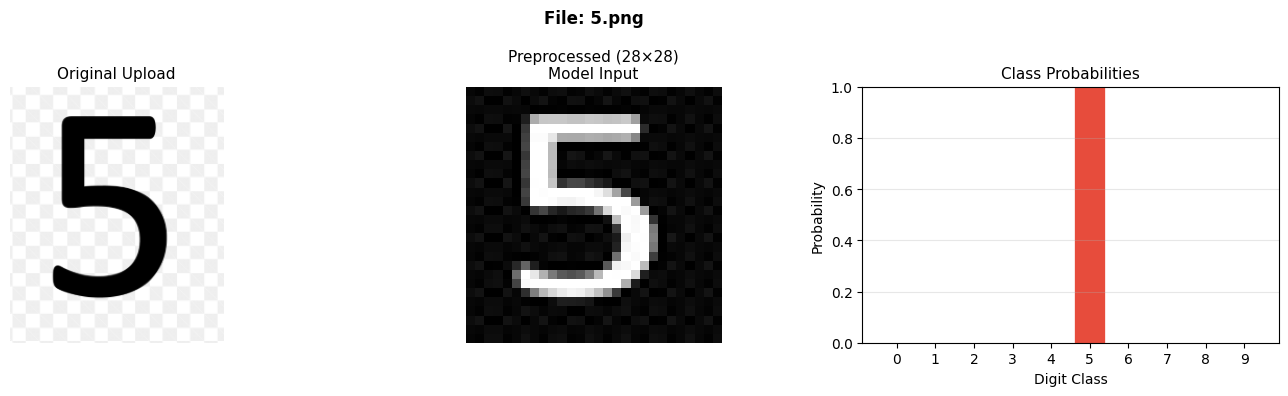

  🔢 Predicted Digit : 5
  💯 Confidence      : 99.99%
  📊 All probabilities:
     0:                                 0.00%
     1:                                 0.00%
     2:                                 0.00%
     3:                                 0.01%
     4:                                 0.00%
     5: █████████████████████████████  99.99% ← predicted
     6:                                 0.00%
     7:                                 0.00%
     8:                                 0.00%
     9:                                 0.00%


In [26]:
print("🔁 Re-run this cell to test another image anytime.\n")
upload_and_predict(model)